In [2]:
import numpy as np
import sympy as sp
from scipy import linalg as la
sp.init_printing() 
np.set_printoptions(precision=3,suppress=True)

#####
<font color="#2c3e50" size="6"><div style="
    font-family: sans-serif;
    font-size: 1.2em;
    font-weight: 700;
    line-height: 1.2;
    background-color: #d9e6f2;
    border-radius: 8px;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    padding: 0.5em 1em;
    margin-top: 1em;
    margin-bottom: 0.6em;
    box-shadow: 0 2px 6px rgba(0,0,0,0.1);
" align="center">
1.7 Fundamental Matrix Subspaces
</div></font>

In this chapter, we will study the four fundamental subspaces associated with a matrix.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Column and Row Spaces</b>
</div></font> 

Most of the subspaces of $\mathbb{R}^n$ arise naturally from matrices. 

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition  </strong> <br> The <strong>column space</strong> of a matrix $A$ is the set of all linear combinations of the columns of $A$. We denote it by $Col(A)$.
</div>


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition  </strong> <br> The <strong>row space</strong> of a matrix $A$ is a set of all linear combinations of the rows of $A$. We denote it by $Row(A)$.
</div>



If $A$ is an $m\times n$ matrix, then 
* $Col(A)$ is the span of the columns of $A$, and therefore it is a subspace of $\mathbb{R}^m$.
* $Row(A)$ is the span of the rows of $A$, and therefore it is a subspace of $\mathbb{R}^n$.

In practice, we are usually interested in finding bases for $Col(A)$ and $Row(A)$. Since both spaces are defined as spans, they already satisfy the spanning property. Therefore, our task is simply to select a subset of vectors that are linearly independent and still span the space. From the previous chapter, we know that the pivot columns identify linearly independent columns. All we need to do is take the pivot columns of $A$. These columns would produce a basis for $Col(A)$. 

But what about the row space? Since $Row(A)=Col(A^T)$, we could transpose the matrix and repeat the process, but there is a more efficient approach. To understand it, we need to know how elementary row operations affect rows and columns. 

* **(Effect on Columns)** Elementary row operations preserve linear relations among the columns, but change the subspace spanned by those columns.
* **(Effect on Rows)** Elementary row operations preserve the subspace spanned by the rows, but may change linear relations among the original rows.


This leads to the following important conclusions:

* To find a basis for $Col(A)$, we row-reduce $A$ to echelon form and identify the pivot columns. Then we take the corresponding columns from the original matrix $A$ (not from the echelon form).

* To find a basis for $Row(A)$, we take the nonzero rows of the echelon form (the pivot rows).

Notice that since both the column space and the row space are determined by the pivot positions, they always have the same dimension.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #dd8452;
    background-color: rgba(250,100,60,0.16);
    margin: 0.4em 0;
">
<strong>⚠️Caution:</strong> We cannot take pivot columns from the row-reduced matrix when finding a basis for $Col(A)$, because row operations may change the subspace spanned by the columns.
Similarly, we cannot simply take the corresponding pivot rows from the original matrix when finding a basis for $Row(A)$, because those rows may not be linearly independent.
</div>

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> An interesting consequence of the effect of row operations on pivot positions is that, for any matrix $A$, the number of pivots in $A$ equals the number of pivots in $A^T$.
</div>

---
**<font color="red">Example 1</font>**

Let $$A=\begin{bmatrix} 1& 2 & 0 & -1 & 3 \\ 2 & 5 & 1 & 0 & 4 \\ 0 & 1 & 1 & 2 & -1 \\ 1 & 3 & 1 & 1 & 2 \end{bmatrix}$$ Find bases for $Col(A)$ and $Row(A)$, state their dimensions, and indicate the Euclidian vector space in which each is a subspace.

**Solution.**

First, we reduce $A$ to echelon form:
$$\require{color}\require{bbox}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\newcommand{\hly}[1]{\bbox[DarkTurquoise, 2pt]{#1}}\begin{bmatrix} 1& 2 & 0 & -1 & 3 \\ 2 & 5 & 1 & 0 & 4 \\ 0 & 1 & 1 & 2 & -1 \\ 1 & 3 & 1 & 1 & 2 \end{bmatrix} \sim \cdots \sim \begin{bmatrix} \hl{1}& 2 & 0 & -1 & 3 \\ 0 & \hl{1} & 1 & 2 & -2 \\ 0 & 0 & 0 & 0 & \hl{1} \\ 0 & 0 & 0 & 0 & 0 \end{bmatrix}$$

There are three pivot positions. Therefore, a basis for the column space consists of columns of $A$ corresponding to the pivot columns (columns 1, 2, and 5).

$$\text{Basis of }Col(A) =\left\{\begin{bmatrix} 1 \\ 2 \\ 0 \\ 1 \end{bmatrix},\begin{bmatrix} 2 \\ 5 \\ 1 \\ 3 \end{bmatrix},\begin{bmatrix} 3 \\ 4 \\-1 \\ 2 \end{bmatrix} \right\}$$

Therefore, $Col(A)$ is a subspace of $\mathbb{R}^4$ and $dim(Col(A)) = 3$.

To find a basis for $Row(A)$, we take the nonzero rows of the echelon form:

$$\text{Basis of }Row(A) =\left\{\begin{bmatrix} 1 & 2 & 0 & -1 & 3 \end{bmatrix},\begin{bmatrix} 0 & 1 & 1 & 2 & -2 \end{bmatrix},\begin{bmatrix} 0 & 0&0& 0 &1\end{bmatrix} \right\}$$

Therefore, $Row(A)$ is a subspace of $\mathbb{R}^5$ and $dim(Row(A)) = 3$.


---

You might be wondering what these two spaces tell us about matrix $A$. Suppose we have an equation $A{\bf x}={\bf b}$, then 
* If $A{\bf x}={\bf b}$ is consistent, then ${\bf b}$ is a linear combination of the columns of $A$, and so ${\bf b} \in Col(A)$.
* If $A{\bf x}={\bf b}$ is inconsistent, then ${\bf b}$ cannot be written as a linear combination of the columns of $A$, and so ${\bf b}$ is not in $Col(A)$.

Therefore, $Col(A)$ consists of all vectors ${\bf b}$ for which $A{\bf x}={\bf b}$ is consistent.

It is a bit trickier to understant $Row(A)$ in this way. Each row of $A$ contributes an equation that restricts the variable vector ${\bf x}$. Therefore, $Row(A)$ tells us which combinations of variables matter. It consists of all the "directions" in the variable space that affect the value of $A{\bf x}$.


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> The number of pivots, $p$, is called the <strong>rank</strong> of $A$. Since $dim(Row(A))$ and $dim(Col(A))$ both equal to $p$, the rank can also be defined as the dimension of the column space or the row space. 
</div>

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Null Space</b>
</div></font> 

Let's recall what we know about homogeneous equations. If $A$ is an $m \times n$ matrix, then the solution set of the homogeneous system $A{\bf x}={\bf 0}$ consists of vectors in $\mathbb{R}^n$. The solutions can be expressed as linear combinations of $k$ linearly independent vectors, where $k$ is the number of free variables. Therefore,
* The solution set of $A{\bf x}={\bf 0}$ forms a subspace of $\mathbb{R}^n$. 
* The vectors obtained from the parametric solution form a basis for this subspace.


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition  </strong> <br> The <strong>null space</strong> of a matrix $A$ is the set of all solutions to the homogeneous equation $A{\bf x}={\bf 0}$. We denote it by $Nul(A)$.
</div>


---
**<font color="red">Example 2</font>**

Let $A=\begin{bmatrix} 1& 2 & 0 & -1 & 3 \\ 2 & 5 & 1 & 0 & 4 \\ 0 & 1 & 1 & 2 & -1 \\ 1 & 3 & 1 & 1 & 2 \end{bmatrix}$ Find a basis for $Nul(A)$ and state its dimension.

**Solution.**

To find the null space, we reduce $A$ to reduced echelon form:
$$\require{color}\require{bbox}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\newcommand{\hly}[1]{\bbox[DarkTurquoise, 2pt]{#1}}\begin{bmatrix} 1& 2 & 0 & -1 & 3 \\ 2 & 5 & 1 & 0 & 4 \\ 0 & 1 & 1 & 2 & -1 \\ 1 & 3 & 1 & 1 & 2 \end{bmatrix} \sim \cdots \sim \begin{bmatrix} 1& 2 & 0 & -1 & 3 \\ 0 & 1 & 1 & 2 & -2 \\ 0 & 0 & 0 & 0 & 1 \\ 0 & 0 & 0 & 0 & 0 \end{bmatrix}
\sim \cdots \sim
\begin{bmatrix} \hl{1}& 0 & -2 & -5 & 0 \\ 0 & \hl{1} & 1 & 2 & 0 \\ 0 & 0 & 0 & 0 & \hl{1} \\ 0 & 0 & 0 & 0 & 0 \end{bmatrix}
$$

We have two free variables, $x_3$ and $x_4$. Let $x_3=t$ and $x_4=s$. Then


$${\bf x}= 
\begin{bmatrix}
x_1 \\x_2\\x_3\\x_4\\x_5\end{bmatrix}=
\begin{bmatrix}
2t +5s \\-t-2s\\t \\ s\\0\end{bmatrix}
=t\begin{bmatrix}2\\-1\\1\\ 0\\ 0\end{bmatrix}+s\begin{bmatrix}5 \\-2\\0\\ 1\\ 0\end{bmatrix}=
span\left(\begin{bmatrix}2\\-1\\1\\ 0\\ 0\end{bmatrix},\begin{bmatrix}5 \\-2\\0\\ 1\\ 0\end{bmatrix} \right)$$

Therefore, $$\text{Basis of }Nul(A)= \left\{\begin{bmatrix}2\\-1\\1\\ 0\\ 0\end{bmatrix},\begin{bmatrix}5 \\-2\\0\\ 1\\ 0\end{bmatrix} \right\}$$
The two vectors are linearly independent and so, $dim(Nul(A))=2$

---

Notice that the dimension of the null space equals the number of free variables.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong> <br> Let $A$ be an $m\times n$ matrix. Then $$rank(A)+dim(Nul(A))=n$$
</div>

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Orthogonal Complements.</b>
</div></font> 

Recall that two vectors ${\bf v}$ and ${\bf u}$ are orthogonal if and only if ${\bf v}\cdot {\bf u}=0$.

Let $S$ be a subspace of $\mathbb{R}^n$. A vector ${\bf v} \in \mathbb{R}^n$ is said to be orthogonal to $S$ if ${\bf v}\cdot {\bf u}=0$ for all vectors ${\bf u} \in S$. The set of all vectors orthogonal to $S$ is called the **orthogonal complement of $S$** and denoted by $S^{\perp}$. 


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong> <br> Let $S$ be a subspace of $\mathbb{R}^n$. Then $S^{\perp}$ is a subspace of $\mathbb{R}^n$ as well.
</div>


**Proof**

To show that $S^{\perp}$ is a subspace of $\mathbb{R}^n$, we need to verify the three subspace properties. 
Let ${\bf v}, {\bf u} \in S^{\perp}$. For every ${\bf s} \in S$ we have

1. ${\bf 0}\cdot {\bf s}=0$. Therefore, the zero vector ${\bf 0}$ belongs to $S^{\perp}$.

2. $({\bf v}+{\bf u})\cdot {\bf s} = {\bf v}\cdot{\bf s}+{\bf u}\cdot{\bf s}=0+0=0$. Therefore, $S^{\perp}$ is closed under addition.

3. $(c{\bf v})\cdot{\bf s}=c({\bf v}\cdot{\bf s})=c0=0$ for any scalar $c$. Therefore, $S^{\perp}$ is closed under scalar multiplication.

Thus, $S^{\perp}$ contains the zero vector and is closed under addition and scalar multiplication, and hence it is a subspace of $\mathbb{R}^n$.

---
 
At first, it may seem difficult to verify that a vector is orthogonal to a subspace, since a subspace usually contains infinitely many vectors. However, the following theorem shows that it is enough to check only finitely many vectors.


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong> <br> Let $S$ be a subspace of $\mathbb{R}^n$ and let $\mathcal{B}=\{ {\bf b}_1, \cdots, {\bf b}_k \}$ be a basis for $S$. If a vector ${\bf v}$ is orthogonal to every basis vector ${\bf b}_i$, then ${\bf v}$ is in $S^{\perp}$.
</div>


**Proof**

Let ${\bf y}$ be a vector in $S$. Since $\mathcal{B}=\{ {\bf b}_1, \cdots, {\bf b}_k \}$ is a basis for $S$, we can express ${\bf y}$ as a linear combination of basis vectors: $${\bf y}=c_1{\bf b}_1+ \cdots + c_k{\bf b}_k$$
for some scalars $c_1, \cdots, c_k$. Then

$${\bf v}\cdot {\bf y} = {\bf v}\cdot(c_1{\bf b}_1+ \cdots + c_k{\bf b}_k)=c_1{\bf v}\cdot{\bf b}_1+\cdots+c_k{\bf v}\cdot{\bf b}_k=c_10+\cdots+c_k0=0$$

Hence, ${\bf v}$ is orthogonal to every vector in $S$, which means ${\bf v} \in S^{\perp}$.

---
**<font color="red">Example 3</font>**

Let $S=span\left(\begin{bmatrix}  -1 \\ 1 \\ 1 \end{bmatrix},\begin{bmatrix}  0 \\ 1 \\ 2 \end{bmatrix}, \begin{bmatrix}  -1 \\ 2 \\ -3 \end{bmatrix}, \begin{bmatrix} -2 \\ 1 \\0 \end{bmatrix} \right)$ and let ${\bf v}=\begin{bmatrix} 1 \\2\\-1 \end{bmatrix}$. Show that ${\bf v} \in S^{\perp}$.

**Solution.**

Let's compute the dot products of ${\bf v}$ with the four vectors in the span $S$:

$$(-1)(1)+(1)(2)+(1)(-1)=0$$
$$(0)(1)+(1)(2)+(2)(-1)=0$$
$$(-1)(1)+(2)(2)+(-3)(-1)=0$$
$$(-2)(1)+(1)(2)+(0)(-1)=0$$

So, ${\bf v}$ is orthogonal to each vector spanning $S$, and hence to every vector in $S$.

---

Another important example of orthogonal complements is the relationship between the null space and the row space.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong> <br> $Row(A)$ and $Nul(A)$ of a matrix $A$ are orthogonal complements.
</div>

**Proof**

Let $A$ be matrix with rows ${\bf a}_1^T, \cdots, {\bf a}_m^T$ and let ${\bf x} \in Nul(A)$. Then ${\bf x}$ is a solution to the homogenous system $A{\bf x}={\bf 0}$

Writing the matrix-vector product row-by-row,

$$A{\bf x}=\begin{bmatrix} {\bf a}_1^T \\ \vdots \\ {\bf a}_m^T \end{bmatrix} {\bf x} = \begin{bmatrix} {\bf a}_1^T  {\bf x} \\ \vdots \\ {\bf a}_m^T  {\bf x} \end{bmatrix} =\begin{bmatrix} {\bf a}_1 \cdot {\bf x} \\ \vdots \\ {\bf a}_m \cdot {\bf x} \end{bmatrix}= \begin{bmatrix} 0 \\ \vdots \\ 0 \end{bmatrix},$$

Therefore, ${\bf a}_i \cdot {\bf x}=0$ for every $i$, which means that ${\bf x}$ is orthogonal to every row of $A$. 

Since $Row(A)$ is the span of the rows of $A$, vector ${\bf x}$ is orthogonal to every vector in $Row(A)$. Because ${\bf x}$ was an arbitrary vector in $Nul(A)$, we conclude that $$Nul(A)^{\perp}=Row(A)$$

---


Since simple, nontrivial subspaces are lines or planes containing the origin, a useful way to visualize orthogonal subspaces is to imagine two perpendicular lines in $\mathbb{R}^2$, or a line perpendicular to a plane in $\mathbb{R}^3$:

<center> <img src="data:image/png;base64,  ...
 " width="60%"> </center>

Notice that, in the two images above, the dimensions of a subspace and its orthogonal complement add up to the dimension of the whole space. This is not a coincidence. Together, the subspace $S$ and its orthogonal complement $S^{\perp}$ span the entire space. In other words, they decompose $\mathbb{R}^n$ into two mutually orthogonal subspaces.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> A subspace $S$ and its orthogonal complement $S^{\perp}$ have only the zero vector in common.
</div>
<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong> <br> Let $S$ be a subspace of $\mathbb{R}^n$. Then $dim(S)+dim(S^{\perp})=n$.
</div>





**Proof**

Let $\left\{ {\bf b}_1, \cdots, {\bf b}_m \right\}$ be a basis for $S$. Let $A$ be a matrix whose rows are basis vectors for $S$: $$A=\begin{bmatrix} {\bf b}_1^T \\ \vdots \\ {\bf b}_m^T \end{bmatrix}$$
Then $Row(A)=S$ and $dim(S)=dim(Row(A))=m$, since basis vectors are linearly independent.

The matrix $A$ is an $m \times n$ matrix with $m$ pivots, and so it has $n-m$ non-pivot columns. Therefore, $dim(Nul(A))=n-m$.

Since $Nul(A)=Row(A)^{\perp}=S^{\perp}$, we have $dim(S^{\perp})=n-m$.

Hence, $dim(S)+dim(S^{\perp}) = m + (n-m)=n$

---

The last two theorems provide an easy way to find the orthogonal complement of a subspace. If we can express a subspace as the span of vectors, we can form a matrix whose rows are those vectors. Then the null space of that matrix is precisely the orthogonal complement.

---
**<font color="red">Example 4</font>**

Let $S=span\left(\begin{bmatrix}  1 \\ 2 \\ 1 \\2 \end{bmatrix},\begin{bmatrix}  -1 \\ -1 \\ 2 \\3 \end{bmatrix}, \begin{bmatrix} 2 \\ 0 \\ 1 \\1 \end{bmatrix} \right)$. Find a basis for $S^{\perp}$

**Solution.**

We form a matrix whose rows are the vectors defining the span, then row-reduce it:

$$\begin{bmatrix} 1 & 2 & 1 &2 \\ -1 & -1 & 2&3 \\ 2 & 0 & 1 &1\end{bmatrix} \sim \cdots \sim \begin{bmatrix} 1 & 0 & 0 & -3/11 \\ 0 & 1 & 0&4/11 \\ 0 & 0 & 1 &17/11\end{bmatrix}$$

We have one free variable, so the solution to $A{\bf x}={\bf 0}$ is 
$${\bf x}=t\begin{bmatrix} 3/11 \\ -4/11 \\ 17/11 \\ 1 \end{bmatrix}$$

A basis for $S^{\perp}$ is also a basis for $Nul(A)$. We can choose any nonzero value for the parameter $t$. Choosing $t=11$ eliminates the fractions:

$$\text{Basis for }S^{\perp}=\left\{\begin{bmatrix} 3 \\ -4 \\ 17 \\ 11 \end{bmatrix} \right\}$$

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Left Null Space</b>
</div></font> 

If $A$ an $m\times n$ matrix, then the row and the null spaces split $\mathbb{R}^n$ into two orthogonal complements. Column space of $A$ is a subspace of $\mathbb{R}^m$, and it would seem we are missing one more subspace, the orthogonal complement of the column space. Since $Col(A)=Row(A^T)$, its orthogonal complement of $Col(A)$ is $Nul(A^T)$. This subspace is called the **left null space**. We usually denote the left null space simply by $Nul(A^T)$.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong> <br> 
    <strong>1.</strong> Let $A$ be an $m\times n$ matrix. Then $rank(A)+dim(Nul(A^T))=m$ <br>
    <strong>2.</strong>  $Col(A)$ and $Nul(A^T)$ of a matrix $A$ are orthogonal complements.
</div>

The relationship between $Nul(A^T)$ and the equation $A{\bf x}={\bf b}$ is tricky as well. Recall that $Col(A)$ consists of all vectors ${\bf b}$ for which the equation $A{\bf x}={\bf b}$ is consistent. Since the subspaces $Nul(A^T)$ and $Col(A)$ are orthogonal subspaces, a vector ${\bf b}$ can belong to $Col(A)$ only if it is orthogonal to every vector in $Nul(A^T)$. In other words, if ${\bf b}$ is not orthogonal to some vector in $Nul(A^T)$, the equation is inconsistent.

---

The four subspaces we have introduced are called the **four fundamental subspaces**. Let us summarize their main properties.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Properties of the fundamental subspaces</strong> <br> 
Let $A$ be an $m\times n$ matrix with $p$ pivot positions. Then <br>

<strong>1.</strong> $Col(A)$ and $Nul(A^T)$ are subspaces of $\mathbb{R}^m$<br>
<strong>2.</strong> $Row(A)$ and $Nul(A)$ are subspaces of $\mathbb{R}^n$<br>
<strong>3.</strong> $dim(Col(A))=dim(Row(A))=p$<br>
<strong>4.</strong> $dim(Nul(A))=n-p$<br>
<strong>5.</strong> $dim(Nul(A^T))=m-p$<br>
<strong>6.</strong> $Nul(A)$ and $Row(A)$ are orthogonal complements.<br>
<strong>7.</strong> $Col(A)$ and $Nul(A^T)$ are orthogonal complements.
</div>


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Matrix-related Subspaces in Python</b>
</div></font> 

We can use SymPy to compute matrix-related subspaces. Its built-in commands automatically return bases for the corresponding spaces. SciPy also provides a function for computing the null space, but it does not provide direct functions for computing the column space or row space. To compute these spaces using SciPy, we would need to use a technique called QR-factorization, which we will study later.

Let's find all four subspaces for the matrix from the Example 1:  $$A=\begin{bmatrix} 1& 2 & 0 & -1 & 3 \\ 2 & 5 & 1 & 0 & 4 \\ 0 & 1 & 1 & 2 & -1 \\ 1 & 3 & 1 & 1 & 2 \end{bmatrix}$$

In [14]:
A=np.array([[1,2,0,-1,3],[2,5,1,0,4],[0,1,1,2,-1],[1,3,1,1,2]])
A_sym=sp.Matrix(A)

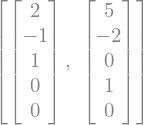

In [15]:
A_sym.nullspace()

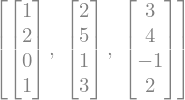

In [16]:
A_sym.columnspace()

In [17]:
A_sym.rowspace()

There is no special command for the left null space. We can find it by computing the null space of the transpose:

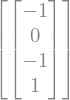

In [18]:
A_sym.T.nullspace()

Here is the null space computed using SciPy:

In [19]:
print(la.null_space(A))

[[ 0.899 -0.16 ]
 [-0.328  0.244]
 [-0.16  -0.899]
 [ 0.244  0.328]
 [ 0.     0.   ]]


At first glance, the null-space bases computed by SymPy and SciPy may appear to be different. However, remember that bases are not unique. The same subspace can have many different bases. SymPy uses techniques similar to those we apply by hand, such as row reduction, so its output typically resembles the basis we would compute manually. SciPy, on the other hand, uses numerical methods. It returns a basis consisting of mutually orthogonal vectors each with the norm $1$. And so, even though the basis vectors look different, they span the same subspace.


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
    
<strong>📌 Note:</strong> Note that at the start of the chapter, we used `np.set_printoptions(precision=3,suppress=True)`. This rounds all outputs by NumPy to three decimal places for readability. This means this is just an approximation of the vectors. This applies to all future outputs in this chapter.
</div>


---

In the next example, we will look at two alternative ways to check linear independence using Python.

---
**<font color="red">Example 5</font>**

Let $\bf{a_1}=\begin{bmatrix} 1 \\ 2 \\ 1 \end{bmatrix}$, $\bf{a_2}=\begin{bmatrix} -1 \\ 3 \\ 2 \end{bmatrix}$ and $\bf{a_3}=\begin{bmatrix} 4 \\ 5 \\ 5 \end{bmatrix}$. Check that the set $\mathcal{A}=\{\bf{a_1},\bf{a_2},\bf{a_3}\}$ forms a basis for $\mathbb{R}^3$.

   
**Solution.**

Since $\mathcal{A}$ contains three vectors in $\mathbb{R}^3$, we only need to check linear independence to see whether they form a basis for $\mathbb{R}^3$.

Let $A=\begin{bmatrix} \bf{a_1}&\bf{a_2}&\bf{a_3}\end{bmatrix}$. If the null space of $A$ is trivial, then $A$ has no free variables and therefore, the three vectors in $\mathcal{A}$ are linearly independent. Otherwise, they are linearly dependent.

In [8]:
At=np.array([[1,2,1],[-1,3,2],[4,5,5]])
A=At.T
print(la.null_space(A))

[]


The other way to check linear independence is to look at the $rank(A)$ using `np.linalg.matrix_rank()`.

In [9]:
print(f'Rank of A is {np.linalg.matrix_rank(A)}')

Rank of A is 3


Since the rank is equal to the number of vectors in $\mathcal{A}$, the vectors are linearly independent.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Matrix Equations with Infinitely Many Solutions</b>
</div></font> 

Recall that standard linear equation solvers typically work when a matrix equation has a unique solution. However, now that we can compute the null space, we can also describe the solution set of systems that have infinitely many solutions.

For a homogeneous system $A{\bf x}={\bf 0}$ the solution set is precisely the null space of $A$. Using SciPy, the command `la.null_space(A)` returns a basis for this solution space.

For a non-homogeneous system $A{\bf x}={\bf b}$, finding the null space alone is not sufficient. The general solution has the form $${\bf x}={\bf x}_p+{\bf x}_h,$$ where ${\bf x}_p$ is a particular solution and ${\bf x}_h$ is in $Nul(A)$. So we need a particular solution as well. There are several ways to find a particular solution. One convenient approach is to use `la.lstsq(A,b)[0]`, which returns the solution to $A{\bf x}={\bf b}$ with the smallest norm; that is, the closest to the origin. (The name of the function refers to "least squares". We will study how it works in a later chapter.)

---
**<font color="red">Example 6</font>**

Let $A=\begin{bmatrix}  3 & 6 & -3\\ 4 & 8 & -4\end{bmatrix}$ and ${\bf b}=\begin{bmatrix} 9 \\ 12 \end{bmatrix}$. Solve $A{\bf x}={\bf 0}$ and $A{\bf x}={\bf b}$

**Solution.**

In [21]:
A=np.array([[3,6,-3],[4,8,-4]])
b=np.array([9,12])

In [22]:
x=la.null_space(A)
print(x)

[[ 0.913 -0.   ]
 [-0.365  0.447]
 [ 0.183  0.894]]


The basis contains two vectors. Solution set of $A{\bf x}={\bf 0}$ consists of all linear combinations of these vectors:

$${\bf x}=t\begin{bmatrix} 0.913 \\ -0.365 \\ 0.183 \end{bmatrix}+s\begin{bmatrix} 0 \\ 0.447 \\ 0.894\end{bmatrix}$$

Solution set of $A{\bf x}={\bf b}$ consists of a particular solution plus an arbitrary linear combination of the two null-space basis vectors. Let us find a particular solution.

In [24]:
x=la.lstsq(A,b)[0]
print(x)

[ 0.5  1.  -0.5]


Therefore, the general solution to the non-homogeneous equation is 

$${\bf x}=\begin{bmatrix} 0.5 \\ 1 \\ -0.5 \end{bmatrix}+t\begin{bmatrix} 0.913 \\ -0.365 \\ 0.183 \end{bmatrix}+s\begin{bmatrix} 0 \\ 0.447 \\ 0.894\end{bmatrix}$$

######
<font color="#0fbf0f" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Exercises</b>
</div></font> 

**1.** 
>In each part of this problem, you are given a matrix and its echelon form. Find bases for the null space, column space, and row space of the matrix, and state their dimensions.  <br><br>
>***a.*** $\begin{bmatrix} 1& 2 & 0 &  1 \\ 2 & 5 & 1 & 3 \\ 1 & 1 & 2 & 0  \end{bmatrix} \sim \cdots \sim \begin{bmatrix} 1& 2 & 0 & 1  \\ 0 & 1 & 1 & 1 \\ 0 & 0 & 3 & 0  \end{bmatrix};  \quad \quad\quad$
>***b.*** $\begin{bmatrix} 1& 2 & 1 &  3 \\ 2 & 4 & 0 & 1 \\ 3 & 6 & 1 & 4  \end{bmatrix} \sim \cdots \sim \begin{bmatrix} 1& 2 & 1 & 3  \\ 0 & 0 & 2 & 5 \\ 0 & 0 & 0 & 0  \end{bmatrix};$  <br><br>
>***c.*** $\begin{bmatrix} 1& 2 & 1  \\ 2 & 5 & 3 \\ 1& 1 & 2  \end{bmatrix} \sim \cdots \sim \begin{bmatrix} 1& 2 & 1   \\ 0 & 1 & 1 \\ 0 & 0 & 2  \end{bmatrix}; \quad \quad\quad\quad \quad\quad$
>***d.*** $\begin{bmatrix} 1& 2 & 3  \\ 2 & 4 & 6 \\ 1& 1 & 2 \\ 3 & 6 & 9 \end{bmatrix} \sim \cdots \sim \begin{bmatrix} 1& 2 & 3  \\ 0 & 1 & 1 \\ 0 & 0 & 0  \\ 0 & 0 & 0 \end{bmatrix}$<br><br>

**2.**
> Find the left null space for the matrices in the problem 1.

**3.**
> Repeat problems 1 and 2 using Python.

**4.**
> For a given matrix $A$ and a vector ${\bf b}$, solve $A{\bf x}={\bf b}$ using Python.<br><br>
> ***a.*** $A=\begin{bmatrix} 1& 2 & 0 &  1 \\ 2 & 1 & 1 & 3 \\ 1 & 6 & 2 & 0  \end{bmatrix}$, ${\bf b}= \begin{bmatrix} 1 \\ 0\\ 1 \end{bmatrix};  \quad \quad\quad$
> ***b.*** $A=\begin{bmatrix} 1& 0 & 5 &  6 \\ 0 & 2 & 1 & -3 \\ 0 & -4 & -2 & 6  \end{bmatrix}$, ${\bf b}= \begin{bmatrix} 0 \\ 1\\ -3\end{bmatrix}$<br><br>


**5.**
>Let $S=span\left(\begin{bmatrix} 2 \\ -1 \\ 1 \\ 1 \end{bmatrix},\begin{bmatrix} 4 \\ -6 \\ 1 \\ 0 \end{bmatrix}, \begin{bmatrix} 1 \\ -4 \\ -3 \\ -2 \end{bmatrix}, \begin{bmatrix} 1 \\ -1 \\ 3 \\1 \end{bmatrix} \right)$, and let ${\bf v}=\begin{bmatrix} 4 \\3\\2\\-7 \end{bmatrix}$. Show that ${\bf v} \in S^{\perp}$.

**6.**
>For each subspace $S$, find basis for the orthogonal complement $S^{\perp}$<br><br>
> ***a.*** $S=span\left(\begin{bmatrix}  1 \\ 0 \\ 1 \end{bmatrix},\begin{bmatrix}  0 \\ 1 \\ 1 \end{bmatrix}, \begin{bmatrix} 1 \\ 1 \\2 \end{bmatrix} \right);  \quad \quad\quad$
>***b.*** $S=span\left(\begin{bmatrix}  1 \\ 0 \\ 1 \\ 0 \\4 \end{bmatrix},\begin{bmatrix}  1 \\ 1 \\ 1 \\2\\0\end{bmatrix}, \begin{bmatrix} 1 \\ -2 \\1 \\2\\0\end{bmatrix} \right)$. <br>

**7.** 
>Repeat problem 6 using Python. (Using SymPy will produce more readable results.)
